# Tourism Package Purchase Prediction
### Visit with Us | Full-Code MLOps Project

**Project focus:** Predicting historical travel-package purchase propensity to prioritise customer outreach.

**Approach:** Exploratory analysis, validated data preparation, ensemble-model tuning, experiment tracking, GitHub Actions automation and Streamlit inference.

---

## 1. Problem Definition

Visit with Us currently relies on manual judgement to identify customers who may purchase a new travel package. This approach is difficult to apply consistently when the prospect pool grows. A prediction system could help the marketing team prioritise leads and use its contact capacity more efficiently.

The aim of this project is to **rank customers before their first sales interaction** using their existing profile and travel preferences. The historical outcome, `ProdTaken`, is binary: **1 = package purchased; 0 = not purchased**.

The analysis addresses three questions:

1. What patterns are associated with historical package purchases?
2. Which supervised learning model identifies prospective buyers most effectively?
3. Can the data-to-model workflow be reproduced through GitHub Actions and served through Streamlit?

**Scope of inference:** The dataset does not identify purchases of the newly introduced *Wellness Tourism Package* separately. Consequently, the fitted model estimates **historical travel-package purchase propensity**, not a prospectively validated wellness-specific conversion probability.

### Data Dictionary

The supplied dataset combines customer profile details, travel preferences, and sales interaction records.

| Group | Variables | Use in this project |
|:--|:--|:--|
| Identifier and outcome | `CustomerID`, `ProdTaken` | Identification and target only |
| Demographics | `Age`, `CityTier`, `Occupation`, `Gender`, `MaritalStatus`, `Designation`, `MonthlyIncome` | Candidate pre-contact predictors |
| Travel preferences and circumstances | `NumberOfPersonVisiting`, `PreferredPropertyStar`, `NumberOfTrips`, `Passport`, `OwnCar`, `NumberOfChildrenVisiting` | Candidate pre-contact predictors |
| Sales interaction | `TypeofContact`, `DurationOfPitch`, `NumberOfFollowups`, `ProductPitched`, `PitchSatisfactionScore` | Descriptive audit only; excluded from pre-contact prediction |

The source file also contains `Unnamed: 0`, an exported row index which is not useful as a predictor.

## 2. Data Understanding and Exploratory Analysis

### 2.1 Libraries and dataset overview

In [ ]:
# Core libraries for data exploration and evaluation
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
CSV_PATH = ROOT / "tourism_project" / "data" / "tourism.csv"
assert CSV_PATH.is_file(), "Expected tourism_project/data/tourism.csv in the project root."

raw = pd.read_csv(CSV_PATH)
print(f"Dataset shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print("Target:", raw["ProdTaken"].value_counts().sort_index().to_dict())
display(raw.head())

Dataset shape: 4,128 rows × 21 columns
Target: {0: 3331, 1: 797}


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.000,Self Enquiry,3,6.000,Salaried,Female,3,3.000,Deluxe,3.000,Single,1.000,1,2,1,0.000,Manager,20993.000
1,1,200001,0,49.000,Company Invited,1,14.000,Salaried,Male,3,4.000,Deluxe,4.000,Divorced,2.000,0,3,1,2.000,Manager,20130.000
2,2,200002,1,37.000,Self Enquiry,1,8.000,Free Lancer,Male,3,4.000,Basic,3.000,Single,7.000,1,3,0,0.000,Executive,17090.000
3,3,200003,0,33.000,Company Invited,1,9.000,Salaried,Female,2,3.000,Basic,3.000,Divorced,2.000,1,5,1,1.000,Executive,17909.000
4,5,200005,0,32.000,Company Invited,1,8.000,Salaried,Male,3,3.000,Basic,3.000,Single,1.000,0,5,1,1.000,Executive,18068.000


In [ ]:
# Compact inspection of data types, missingness, uniqueness and distributions
inspection = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(dropna=True)
})
display(inspection)
display(raw[["Age", "MonthlyIncome", "NumberOfTrips",
             "NumberOfPersonVisiting", "PreferredPropertyStar"]].describe().T)
print("Duplicate customer IDs:", raw["CustomerID"].duplicated().sum())
print("Exact duplicate rows:", raw.duplicated().sum())

,dtype,missing,unique
Unnamed: 0,int64,0,4128
CustomerID,int64,0,4128
ProdTaken,int64,0,2
Age,float64,0,44
TypeofContact,object,0,2
CityTier,int64,0,3
DurationOfPitch,float64,0,33
Occupation,object,0,4
Gender,object,0,3
NumberOfPersonVisiting,int64,0,5


,count,mean,std,min,25%,50%,75%,max
Age,4128.000,37.232,9.175,18.000,31.000,36.000,43.000,61.000
MonthlyIncome,4128.000,23178.464,4506.615,1000.000,20751.000,22418.000,25301.000,98678.000
NumberOfTrips,4128.000,3.295,1.856,1.000,2.000,3.000,4.000,22.000
NumberOfPersonVisiting,4128.000,2.949,0.719,1.000,2.000,3.000,3.000,5.000
PreferredPropertyStar,4128.000,3.578,0.795,3.000,3.000,3.000,4.000,5.000


Duplicate customer IDs: 0
Exact duplicate rows: 0


**Observation:**
- The dataset contains **4,128 customers and 21 columns**. The purchase outcome is available for every record.
- There are **no missing values or duplicate customer IDs** in the dataset.
- Customer IDs and the exported index identify records; they do not describe purchasing behaviour.

### 2.2 Data quality and unusual values

In [ ]:
# Check inconsistent category labels and extreme numerical observations
print("Gender labels:")
display(raw["Gender"].value_counts().rename_axis("Gender").to_frame("Customers"))

print("Marital-status labels:")
display(raw["MaritalStatus"].value_counts().rename_axis("Status").to_frame("Customers"))

print("Selected numerical ranges:")
display(raw[["Age", "NumberOfTrips", "MonthlyIncome", "DurationOfPitch"]]
        .agg(["min", "median", "max"]).T)

print("Customers reporting at least 19 annual trips:",
      int((raw["NumberOfTrips"] >= 19).sum()))
print("Product pitched versus designation:")
display(pd.crosstab(raw["ProductPitched"], raw["Designation"]))

Gender labels:


,Customers
Gender,
Male,2463
Female,1510
Fe Male,155


Marital-status labels:


,Customers
Status,
Married,1990
Divorced,789
Unmarried,682
Single,667


Selected numerical ranges:


,min,median,max
Age,18.000,36.000,61.000
NumberOfTrips,1.000,3.000,22.000
MonthlyIncome,1000.000,22418.000,98678.000
DurationOfPitch,5.000,14.000,127.000


Customers reporting at least 19 annual trips: 4
Product pitched versus designation:


Designation,AVP,Executive,Manager,Senior Manager,VP
ProductPitched,,,,,
Basic,0,1615,0,0,0
Deluxe,0,0,1422,0,0
King,0,0,0,0,104
Standard,0,0,0,737,0
Super Deluxe,250,0,0,0,0


**Observation:**
- `Fe Male` is a spelling variation of `Female` and affects **155 records**; it will be standardised during cleaning.
- `Single` and `Unmarried` occur as separate source categories. They are retained until their business definitions are confirmed.
- Four customers report **19–22 annual trips**, while income reaches **98,678** (source units).
- `ProductPitched` maps exactly to `Designation` in this sample. This relationship could reflect the historical sales process, so the product pitched is excluded from pre-contact scoring.

### 2.3 Univariate analysis

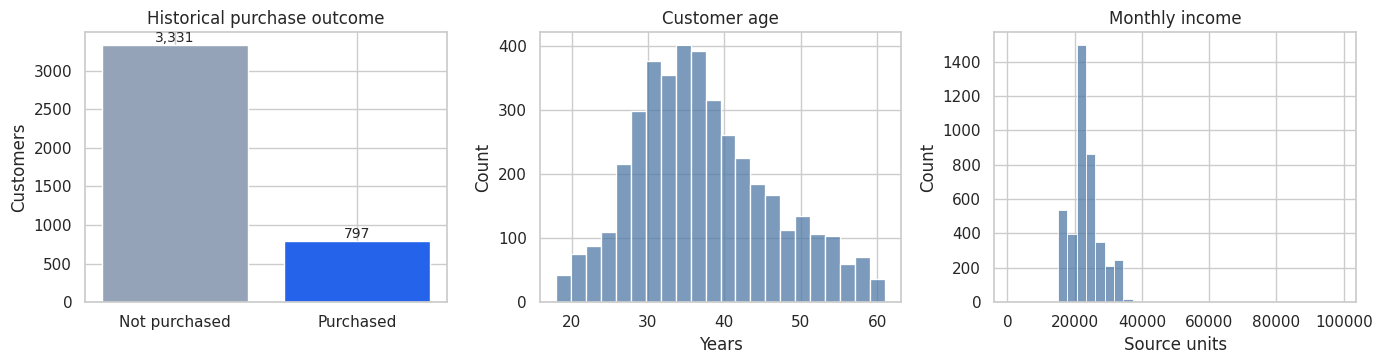

Historical purchase rate: 19.3%
Age mean / median: 37.2 / 36 years


In [ ]:
# Target balance and numerical distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
counts = raw["ProdTaken"].value_counts().reindex([0, 1])
axes[0].bar(["Not purchased", "Purchased"], counts.values, color=["#94a3b8", "#2563eb"])
axes[0].set_title("Historical purchase outcome")
axes[0].set_ylabel("Customers")
for i, n in enumerate(counts):
    axes[0].text(i, n + 40, f"{n:,}", ha="center", fontsize=10)

sns.histplot(raw["Age"], bins=22, color="#4f79a6", ax=axes[1])
axes[1].set_title("Customer age")
axes[1].set_xlabel("Years")

sns.histplot(raw["MonthlyIncome"], bins=35, color="#4f79a6", ax=axes[2])
axes[2].set_title("Monthly income")
axes[2].set_xlabel("Source units")
plt.tight_layout()
plt.show()

print(f"Historical purchase rate: {raw['ProdTaken'].mean():.1%}")
print(f"Age mean / median: {raw['Age'].mean():.1f} / {raw['Age'].median():.0f} years")

**Observation:**
- Only **797 of 4,128 customers (19.3%)** purchased a package. The target is imbalanced, so accuracy alone would give an incomplete assessment of model quality.
- Customer ages are concentrated around the mid-30s (mean **37.2 years**).
- Monthly income is right-skewed, with a small number of unusually high values.

### 2.4 Bivariate analysis: purchase behaviour by customer segment

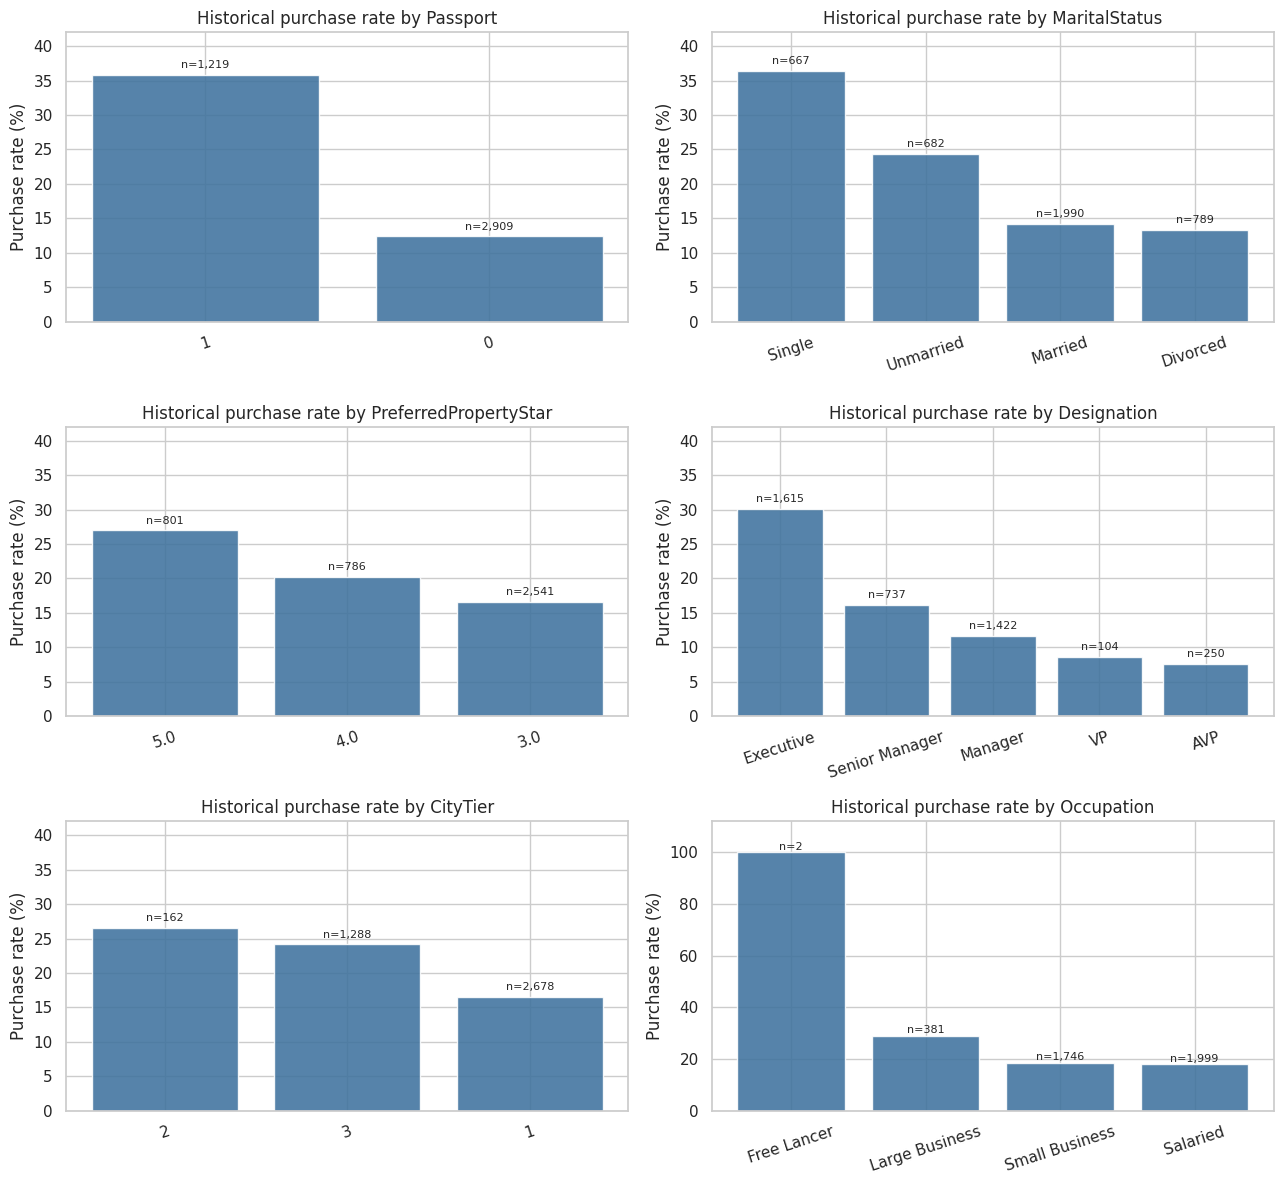


Passport


,customers,buyers,purchase_rate_%
Passport,,,
1,1219,437,35.800
0,2909,360,12.400



MaritalStatus


,customers,buyers,purchase_rate_%
MaritalStatus,,,
Single,667,243,36.400
Unmarried,682,166,24.300
Married,1990,283,14.200
Divorced,789,105,13.300



PreferredPropertyStar


,customers,buyers,purchase_rate_%
PreferredPropertyStar,,,
5.000,801,216,27.000
4.000,786,159,20.200
3.000,2541,422,16.600



Designation


,customers,buyers,purchase_rate_%
Designation,,,
Executive,1615,485,30.000
Senior Manager,737,119,16.100
Manager,1422,165,11.600
VP,104,9,8.700
AVP,250,19,7.600


In [ ]:
# Compare observed conversion rates across relevant pre-contact fields
def purchase_rates(feature):
    result = (raw.groupby(feature, dropna=False)["ProdTaken"]
                .agg(customers="size", buyers="sum", purchase_rate="mean"))
    return result.sort_values("purchase_rate", ascending=False)

segments = ["Passport", "MaritalStatus", "PreferredPropertyStar",
            "Designation", "CityTier", "Occupation"]
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for feature, ax in zip(segments, axes.ravel()):
    summary = purchase_rates(feature).reset_index()
    bars = ax.bar(summary[feature].astype(str), summary["purchase_rate"] * 100,
                  color="#3f729e", alpha=.88)
    ax.set_title(f"Historical purchase rate by {feature}")
    ax.set_ylabel("Purchase rate (%)")
    ax.set_ylim(0, max(42, summary["purchase_rate"].max() * 112))
    ax.tick_params(axis="x", rotation=18)
    for bar, count in zip(bars, summary["customers"]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1, f"n={count:,}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

# Print the rates and sample sizes for the most business-relevant groups.
for feature in ["Passport", "MaritalStatus", "PreferredPropertyStar", "Designation"]:
    print(f"\n{feature}")
    summary = purchase_rates(feature).copy()
    summary["purchase_rate"] = (summary["purchase_rate"] * 100).round(1)
    display(summary.rename(columns={"purchase_rate": "purchase_rate_%"}))

**Observation:**
- Passport holders have a **35.8%** historical purchase rate, compared with **12.4%** for customers without passports.
- Customers marked `Single` have a **36.4%** purchase rate, compared with **14.2%** among married customers.
- Five-star hotel preference is associated with a **27.0%** purchase rate, compared with **16.6%** for three-star preference.
- The `Free Lancer` group contains only **two customers**. Its apparent 100% purchase rate is too unstable to support a meaningful marketing conclusion.

These are **descriptive associations**, not proof that any attribute causes a purchase.

### 2.5 Feature selection and prediction timing

The model is intended to score leads **before the first sales contact**. Using pitch satisfaction, follow-up counts or pitch duration would introduce information unavailable at that decision point. Contact method and pitched product are also excluded because they reflect the sales process or assignment.

The final feature set contains **13 pre-contact fields**, comprising demographic and travel-related information. Numerical missing values, if they occur in future scoring data, will be imputed inside the training pipeline; categorical values will be encoded using training-only fitted transformations.

**Observation:**
- Excluding the five sales-process variables makes the scoring workflow consistent with the stated business decision.
- Keeping preprocessing within the fitted model pipeline prevents statistics from the holdout set from influencing training.

## 3. Data Registration




### 3.1 Central project configuration

In [ ]:
%%writefile tourism_project/model_building/config.py
"""Shared, leakage-safe schema for prospective customer scoring."""
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[1]
REPO_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "tourism.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_PATH = PROJECT_ROOT / "deployment" / "best_model.joblib"
METADATA_PATH = PROJECT_ROOT / "deployment" / "model_metadata.json"
TARGET = "ProdTaken"
ID_COLUMNS = ["CustomerID", "Unnamed: 0"]
# These fields are generated during/after the sales interaction, not at initial lead scoring.
POST_CONTACT_COLUMNS = ["TypeofContact", "DurationOfPitch", "NumberOfFollowups",
                        "ProductPitched", "PitchSatisfactionScore"]
CATEGORICAL_COLUMNS = ["Occupation", "Gender", "MaritalStatus", "Designation", "CityTier"]
NUMERIC_COLUMNS = ["Age", "NumberOfPersonVisiting", "PreferredPropertyStar",
                   "NumberOfTrips", "Passport", "OwnCar", "NumberOfChildrenVisiting",
                   "MonthlyIncome"]
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS
REQUIRED_COLUMNS = ["CustomerID", TARGET] + FEATURE_COLUMNS + POST_CONTACT_COLUMNS
SEED = 42


Overwriting tourism_project/model_building/config.py


### 3.2 Registration and validation

In [ ]:
%%writefile tourism_project/model_building/data_register.py
"""Register the repository-held raw CSV with schema, uniqueness and target checks."""
from __future__ import annotations
import argparse
import json
import pandas as pd
from .config import DATA_PATH, OUTPUT_DIR, REQUIRED_COLUMNS, TARGET


def validate_dataset(csv_path=DATA_PATH, report_path=None):
    source = pd.read_csv(csv_path)
    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(source.columns))
    if missing_columns:
        raise ValueError(f"Required columns missing from dataset: {missing_columns}")
    if source.empty:
        raise ValueError("Dataset is empty")
    if source["CustomerID"].isna().any() or source["CustomerID"].duplicated().any():
        raise ValueError("CustomerID must be non-null and unique")
    if source[TARGET].isna().any() or not set(source[TARGET].unique()).issubset({0, 1}):
        raise ValueError("ProdTaken must contain only non-null binary values 0 and 1")
    if source[TARGET].nunique() != 2:
        raise ValueError("Both outcome classes are required for model evaluation")
    report = {
        "dataset": str(csv_path), "rows": len(source), "columns": len(source.columns),
        "unique_customers": int(source.CustomerID.nunique()),
        "duplicate_rows": int(source.duplicated().sum()),
        "missing_cells": int(source.isna().sum().sum()),
        "missing_by_column": {k:int(v) for k,v in source.isna().sum().items() if v},
        "outcomes": {str(k):int(v) for k,v in source[TARGET].value_counts().sort_index().items()},
        "historical_purchase_rate": round(float(source[TARGET].mean()), 6)
    }
    report_path = OUTPUT_DIR / "registration_report.json" if report_path is None else report_path
    report_path.parent.mkdir(parents=True, exist_ok=True)
    report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2))
    return report

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Validate tourism.csv against expected data dictionary")
    parser.add_argument("--csv", type=str, default=str(DATA_PATH))
    args = parser.parse_args()
    validate_dataset(args.csv)


Overwriting tourism_project/model_building/data_register.py


In [ ]:
from tourism_project.model_building.data_register import validate_dataset
registration = validate_dataset()
assert registration["rows"] == len(raw)
print("Registration validation: PASSED")

{
  "dataset": "/mnt/data/Visit_With_Us_MLOps/tourism_project/data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "unique_customers": 4128,
  "duplicate_rows": 0,
  "missing_cells": 0,
  "missing_by_column": {},
  "outcomes": {
    "0": 3331,
    "1": 797
  },
  "historical_purchase_rate": 0.193072
}
Registration validation: PASSED


**Observation:**
- The schema, unique-customer check and binary target validation pass on the supplied data.
- The generated `registration_report.json` records dataset size, missingness and class distribution, providing an auditable first stage of the MLOps workflow.

## 4. Data Preparation

The cleaned data is split into a **training set (80%)** and an untouched **test set (20%)**, stratified by the purchase outcome. All transformations that learn from data are fitted during model training, not on the full dataset.

### 4.1 Cleaning and stratified split

In [ ]:
%%writefile tourism_project/model_building/prep.py
"""Deterministic preprocessing and stratified holdout; no holdout-driven imputation."""
from __future__ import annotations
import json
import pandas as pd
from sklearn.model_selection import train_test_split
from .config import (DATA_PATH, OUTPUT_DIR, TARGET, FEATURE_COLUMNS,
                     CATEGORICAL_COLUMNS, NUMERIC_COLUMNS, SEED)
from .data_register import validate_dataset


def clean_data(df):
    """Apply canonical labels and remove identifiers and post-contact features.

    Numeric missingness is retained here and imputed using *training folds only*
    within the modeling pipeline, avoiding information leakage.
    """
    df = df.copy()
    df["Gender"] = (df["Gender"].astype("string").str.strip()
                    .replace({"Fe Male": "Female"}))
    for column in (set(CATEGORICAL_COLUMNS) - {"CityTier"}):
        df[column] = df[column].astype("string").str.strip().replace({"": pd.NA})
        # Object strings are supported reliably by OneHotEncoder across environments.
        df[column] = df[column].astype(object).where(df[column].notna(), None)
    for column in NUMERIC_COLUMNS + ["CityTier"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")
    df[TARGET] = pd.to_numeric(df[TARGET], errors="raise").astype(int)
    return df[FEATURE_COLUMNS + [TARGET]]


def prepare_data(csv_path=DATA_PATH, output_dir=OUTPUT_DIR, test_size=0.20):
    validate_dataset(csv_path)
    raw = pd.read_csv(csv_path)
    cleaned = clean_data(raw)
    X = cleaned[FEATURE_COLUMNS]
    y = cleaned[TARGET]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=SEED, stratify=y
    )
    output_dir.mkdir(parents=True, exist_ok=True)
    for filename, df in [("Xtrain.csv", X_train), ("Xtest.csv", X_test),
                         ("ytrain.csv", y_train.to_frame()), ("ytest.csv", y_test.to_frame())]:
        df.reset_index(drop=True).to_csv(output_dir / filename, index=False)
    report = {
        "training_rows": len(X_train), "holdout_rows": len(X_test),
        "training_purchase_rate": round(float(y_train.mean()), 6),
        "holdout_purchase_rate": round(float(y_test.mean()), 6),
        "available_at_scoring": FEATURE_COLUMNS,
        "excluded_post_contact_fields": ["TypeofContact", "DurationOfPitch",
                                         "NumberOfFollowups", "ProductPitched", "PitchSatisfactionScore"],
        "gender_typo_normalized": int(raw["Gender"].eq("Fe Male").sum())
    }
    (output_dir / "preparation_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    print(json.dumps(report, indent=2))
    return X_train, X_test, y_train, y_test

if __name__ == "__main__":
    prepare_data()


Overwriting tourism_project/model_building/prep.py


In [ ]:
from tourism_project.model_building.prep import clean_data, prepare_data
from tourism_project.model_building.config import (
    FEATURE_COLUMNS, OUTPUT_DIR, MODEL_PATH, METADATA_PATH
)

X_train, X_test, y_train, y_test = prepare_data()

display(pd.DataFrame({
    "partition": ["Training", "Testing"],
    "customers": [len(X_train), len(X_test)],
    "purchase_rate_%": [round(100 * y_train.mean(), 2),
                         round(100 * y_test.mean(), 2)]
}))
print("Model input count:", len(X_train.columns))
print("Excluded sales interaction fields present:",
      bool(set(["DurationOfPitch", "NumberOfFollowups", "ProductPitched",
                "PitchSatisfactionScore", "TypeofContact"]) & set(X_train.columns)))
print("Created split files:", sorted(p.name for p in OUTPUT_DIR.glob("*train.csv")))

{
  "dataset": "/mnt/data/Visit_With_Us_MLOps/tourism_project/data/tourism.csv",
  "rows": 4128,
  "columns": 21,
  "unique_customers": 4128,
  "duplicate_rows": 0,
  "missing_cells": 0,
  "missing_by_column": {},
  "outcomes": {
    "0": 3331,
    "1": 797
  },
  "historical_purchase_rate": 0.193072
}


{
  "training_rows": 3302,
  "holdout_rows": 826,
  "training_purchase_rate": 0.193216,
  "holdout_purchase_rate": 0.192494,
  "available_at_scoring": [
    "Age",
    "NumberOfPersonVisiting",
    "PreferredPropertyStar",
    "NumberOfTrips",
    "Passport",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "MonthlyIncome",
    "Occupation",
    "Gender",
    "MaritalStatus",
    "Designation",
    "CityTier"
  ],
  "excluded_post_contact_fields": [
    "TypeofContact",
    "DurationOfPitch",
    "NumberOfFollowups",
    "ProductPitched",
    "PitchSatisfactionScore"
  ],
  "gender_typo_normalized": 155
}


,partition,customers,purchase_rate_%
0,Training,3302,19.320
1,Testing,826,19.250


Model input count: 13
Excluded sales interaction fields present: False
Created split files: ['Xtrain.csv', 'ytrain.csv']


## 5. Model Development and Experiment Tracking

Two tree-based ensembles are evaluated: **Random Forest** and **Gradient Boosting**. Model parameters are tuned with **three-fold stratified cross-validation** on the training partition.

**Selection metric — average precision:** Because purchases are relatively infrequent, the precision–recall trade-off is more useful than accuracy alone. The holdout set is reserved for evaluating the chosen model after tuning.

### 5.1 Training, cross-validation and experiment logging

In [ ]:
%%writefile tourism_project/model_building/train.py
"""Fit models, tune average precision, log experiments and export the winner.

MLflow uses a local file store in Actions, archived as a workflow artifact. For an
offline notebook runtime without MLflow, a complete JSON experiment ledger is
still written; CI installs MLflow and performs full tracking.
"""
from __future__ import annotations
import json
from datetime import datetime, timezone
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, brier_score_loss)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from .config import (OUTPUT_DIR, MODEL_PATH, METADATA_PATH, TARGET, SEED,
                     FEATURE_COLUMNS, CATEGORICAL_COLUMNS, NUMERIC_COLUMNS)


def top_fraction_metrics(y_true, probabilities, fraction=0.20):
    """Assess how effectively a fixed-size contact list captures past buyers."""
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    size = max(1, int(np.ceil(len(y_true) * fraction)))
    chosen = np.argsort(-probabilities, kind="stable")[:size]
    selected_positive = int(y_true[chosen].sum())
    precision = selected_positive / size
    baseline = float(y_true.mean())
    return {
        "top20_precision": float(precision),
        "top20_recall": float(selected_positive / max(1, int(y_true.sum()))),
        "top20_lift": float(precision / baseline) if baseline > 0 else 0.0,
        "top20_contact_count": int(size), "top20_actual_buyers": selected_positive
    }


def build_pipeline(estimator):
    transformer = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), NUMERIC_COLUMNS),
            ("cat", Pipeline(steps=[
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
            ]), CATEGORICAL_COLUMNS)
        ], remainder="drop", verbose_feature_names_out=False
    )
    return Pipeline(steps=[("preprocessor", transformer), ("classifier", estimator)])


def candidate_grids():
    return {
        "RandomForest": (
            RandomForestClassifier(random_state=SEED, class_weight="balanced_subsample", n_jobs=1),
            {"classifier__n_estimators": [150, 250],
             "classifier__max_depth": [8, None],
             "classifier__min_samples_leaf": [2, 5]}
        ),
        "GradientBoosting": (
            GradientBoostingClassifier(random_state=SEED),
            {"classifier__n_estimators": [100, 180],
             "classifier__learning_rate": [0.05, 0.10],
             "classifier__max_depth": [2]}
        )
    }


def train_model(split_dir=OUTPUT_DIR, model_path=MODEL_PATH, metadata_path=METADATA_PATH):
    X_train = pd.read_csv(split_dir / "Xtrain.csv")
    X_test = pd.read_csv(split_dir / "Xtest.csv")
    y_train = pd.read_csv(split_dir / "ytrain.csv")[TARGET].astype(int)
    y_test = pd.read_csv(split_dir / "ytest.csv")[TARGET].astype(int)
    # Data contracts: prohibit accidentally training with retrospective inputs.
    if X_train.columns.tolist() != FEATURE_COLUMNS or X_test.columns.tolist() != FEATURE_COLUMNS:
        raise ValueError("Feature order or pre-contact schema does not match config.py")
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    leaderboard = []
    all_trials = []
    winners = {}

    # Soft availability check is solely for offline execution without network.
    try:
        import mlflow
        mlflow.set_tracking_uri((split_dir / "mlruns").resolve().as_uri())
        mlflow.set_experiment("Tourism-PreContact-Propensity")
        tracking_enabled = True
    except ImportError:
        mlflow = None
        tracking_enabled = False
        print("Local MLflow unavailable; full trial log saved to JSON. GitHub Actions installs MLflow.")

    for name, (estimator, grid_params) in candidate_grids().items():
        search = GridSearchCV(
            build_pipeline(estimator), grid_params, cv=cv, scoring="average_precision",
            n_jobs=1, refit=True, verbose=0, return_train_score=False
        )
        search.fit(X_train, y_train)
        trials = []
        for index, params in enumerate(search.cv_results_["params"]):
            trial = {
                "model": name, "trial": index + 1,
                "params": {key: (None if val is None else val) for key, val in params.items()},
                "mean_cv_average_precision": float(search.cv_results_["mean_test_score"][index]),
                "std_cv_average_precision": float(search.cv_results_["std_test_score"][index])
            }
            trials.append(trial)
            all_trials.append(trial)
            if tracking_enabled:
                with mlflow.start_run(run_name=f"{name}-trial-{index + 1}"):
                    mlflow.log_params({k: "None" if v is None else v for k, v in params.items()})
                    mlflow.log_metric("cv_average_precision", trial["mean_cv_average_precision"])
                    mlflow.log_metric("cv_average_precision_std", trial["std_cv_average_precision"])
        leaderboard.append({"model": name,
                            "cv_average_precision": float(search.best_score_),
                            "best_params": search.best_params_,
                            "trials": len(trials)})
        winners[name] = search.best_estimator_
        print(f"{name}: best CV average precision={search.best_score_:.4f}; "
              f"best params={search.best_params_}")

    # Holdout is deliberately NOT used to select model family or hyperparameters.
    chosen = max(leaderboard, key=lambda row: row["cv_average_precision"])
    final_model = winners[chosen["model"]]
    prob = final_model.predict_proba(X_test)[:, 1]
    label = (prob >= 0.50).astype(int)
    metrics = {
        "average_precision": float(average_precision_score(y_test, prob)),
        "roc_auc": float(roc_auc_score(y_test, prob)),
        "precision_at_0_5": float(precision_score(y_test, label, zero_division=0)),
        "recall_at_0_5": float(recall_score(y_test, label, zero_division=0)),
        "f1_at_0_5": float(f1_score(y_test, label, zero_division=0)),
        "balanced_accuracy_at_0_5": float(balanced_accuracy_score(y_test, label)),
        "brier_score": float(brier_score_loss(y_test, prob)),
        **top_fraction_metrics(y_test, prob)
    }
    # Data summary is for audit and does not imply wellness-specific target validation.
    metadata = {
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "trained_on": "historical generic travel-package purchase outcomes",
        "not_yet_validated_on": "new Wellness Tourism Package",
        "scoring_point": "before sales contact",
        "model_family": chosen["model"],
        "selection_criterion": "3-fold stratified CV average precision on training data",
        "cv_average_precision": chosen["cv_average_precision"],
        "best_params": chosen["best_params"],
        "feature_names": FEATURE_COLUMNS,
        "decision_threshold": 0.5,
        "test_rows": int(len(y_test)),
        "holdout_positive_rate": float(y_test.mean()),
        "test_metrics": metrics,
        "confusion_matrix_0_5": confusion_matrix(y_test, label).tolist(),
        "mlflow_tracking_enabled": tracking_enabled,
        "candidate_models": leaderboard
    }
    model_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_model, model_path, compress=3)
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    (split_dir / "experiment_trials.json").write_text(json.dumps(all_trials, indent=2), encoding="utf-8")
    (split_dir / "holdout_predictions.csv").write_text(
        pd.DataFrame({"actual": y_test, "pred_probability": prob,
                      "predicted_at_0_5": label}).to_csv(index=False), encoding="utf-8")
    if tracking_enabled:
        with mlflow.start_run(run_name=f"CHAMPION-{chosen['model']}"):
            mlflow.log_param("model_family", chosen["model"])
            mlflow.log_params({k: "None" if v is None else v for k,v in chosen["best_params"].items()})
            mlflow.log_metrics({k:v for k,v in metrics.items() if isinstance(v, (float,int))})
            mlflow.log_metric("best_cv_average_precision", chosen["cv_average_precision"])
            mlflow.log_artifact(str(model_path), artifact_path="model")
            mlflow.log_artifact(str(metadata_path), artifact_path="evaluation")
            mlflow.log_artifact(str(split_dir / "experiment_trials.json"), artifact_path="evaluation")
    print(json.dumps({"selected_model": chosen["model"], "cv_ap": chosen["cv_average_precision"],
                      "holdout_metrics": metrics}, indent=2))
    return final_model, metadata

if __name__ == "__main__":
    train_model()


Overwriting tourism_project/model_building/train.py


In [ ]:
from tourism_project.model_building.train import train_model

best_model, model_card = train_model()
assert MODEL_PATH.exists() and METADATA_PATH.exists()
print("Saved model:", MODEL_PATH.relative_to(ROOT))
print("Selected algorithm:", model_card["model_family"])

Local MLflow unavailable; full trial log saved to JSON. GitHub Actions installs MLflow.


RandomForest: best CV average precision=0.7043; best params={'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 150}


GradientBoosting: best CV average precision=0.6061; best params={'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 180}


{
  "selected_model": "RandomForest",
  "cv_ap": 0.7043494647703085,
  "holdout_metrics": {
    "average_precision": 0.7254959782932485,
    "roc_auc": 0.9150990542464618,
    "precision_at_0_5": 0.7338709677419355,
    "recall_at_0_5": 0.5723270440251572,
    "f1_at_0_5": 0.6431095406360424,
    "balanced_accuracy_at_0_5": 0.7614258908281708,
    "brier_score": 0.09400373743321178,
    "top20_precision": 0.6325301204819277,
    "top20_recall": 0.660377358490566,
    "top20_lift": 3.285974085019322,
    "top20_contact_count": 166,
    "top20_actual_buyers": 105
  }
}
Saved model: tourism_project/deployment/best_model.joblib
Selected algorithm: RandomForest


### 5.2 Hyperparameter search results

,model,trials,cv_average_precision,best_params
0,RandomForest,8,0.704,"{'classifier__max_depth': None, 'classifier__m..."
1,GradientBoosting,4,0.606,"{'classifier__learning_rate': 0.1, 'classifier..."


,model,trial,mean_cv_average_precision,std_cv_average_precision,params
4,RandomForest,5,0.704,0.019,"{'classifier__max_depth': None, 'classifier__m..."
5,RandomForest,6,0.703,0.018,"{'classifier__max_depth': None, 'classifier__m..."
7,RandomForest,8,0.648,0.020,"{'classifier__max_depth': None, 'classifier__m..."
6,RandomForest,7,0.646,0.020,"{'classifier__max_depth': None, 'classifier__m..."
0,RandomForest,1,0.639,0.027,"{'classifier__max_depth': 8, 'classifier__min_..."
1,RandomForest,2,0.638,0.026,"{'classifier__max_depth': 8, 'classifier__min_..."


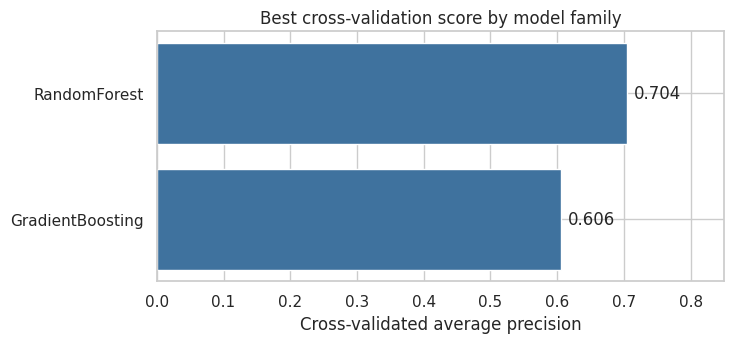

In [ ]:
# Compare model families and inspect the trial-level results
trials = pd.read_json(OUTPUT_DIR / "experiment_trials.json")
leaderboard = pd.DataFrame(model_card["candidate_models"])
leaderboard = leaderboard.sort_values("cv_average_precision", ascending=False)
display(leaderboard[["model", "trials", "cv_average_precision", "best_params"]])

best_trials = (trials.sort_values("mean_cv_average_precision", ascending=False)
                  [["model", "trial", "mean_cv_average_precision", "std_cv_average_precision", "params"]]
                  .head(6))
display(best_trials)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(leaderboard["model"], leaderboard["cv_average_precision"], color="#3f729e")
ax.set_xlim(0, 0.85)
ax.invert_yaxis()
ax.set_xlabel("Cross-validated average precision")
ax.set_title("Best cross-validation score by model family")
for pos, value in enumerate(leaderboard["cv_average_precision"]):
    ax.text(value + .01, pos, f"{value:.3f}", va="center")
plt.tight_layout()
plt.show()

**Observation:**
- **12 hyperparameter combinations** were assessed: eight Random Forest and four Gradient Boosting configurations.
- Random Forest performed better on the selection metric (**0.704** average precision) than Gradient Boosting (**0.606**) in training cross-validation.
- The selected Random Forest uses **150 trees**, **minimum leaf size 2**, and **no maximum-depth restriction**.
- Individual trial parameters and scores are saved in `experiment_trials.json`; the training script also logs them to MLflow when installed (as configured in GitHub Actions).

## 6. Final Model Evaluation

The selected model is evaluated once against the **826 previously unseen customer records**. The 50% classification threshold is reported for interpretability; the business use case is primarily lead ranking.

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)

pred = pd.read_csv(OUTPUT_DIR / "holdout_predictions.csv")
metrics = model_card["test_metrics"]
report = pd.DataFrame({
    "Metric": ["Average precision", "ROC-AUC", "Precision at 0.50",
               "Recall at 0.50", "F1 at 0.50", "Balanced accuracy",
               "Brier score"],
    "Holdout": [metrics["average_precision"], metrics["roc_auc"],
                metrics["precision_at_0_5"], metrics["recall_at_0_5"],
                metrics["f1_at_0_5"], metrics["balanced_accuracy_at_0_5"],
                metrics["brier_score"]]
})
display(report.style.format({"Holdout": "{:.3f}"}))
print("Confusion matrix [TN, FP; FN, TP]:", model_card["confusion_matrix_0_5"])

,Metric,Holdout
0,Average precision,0.725
1,ROC-AUC,0.915
2,Precision at 0.50,0.734
3,Recall at 0.50,0.572
4,F1 at 0.50,0.643
5,Balanced accuracy,0.761
6,Brier score,0.094


Confusion matrix [TN, FP; FN, TP]: [[634, 33], [68, 91]]


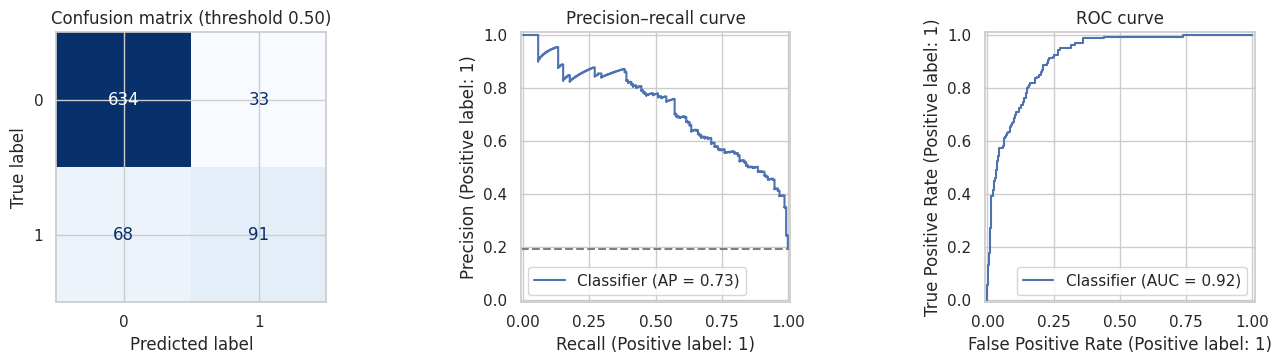

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ConfusionMatrixDisplay.from_predictions(pred["actual"], pred["predicted_at_0_5"],
                                        ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (threshold 0.50)")
PrecisionRecallDisplay.from_predictions(pred["actual"], pred["pred_probability"],
                                        ax=axes[1])
axes[1].axhline(model_card["holdout_positive_rate"], color="gray", ls="--")
axes[1].set_title("Precision–recall curve")
RocCurveDisplay.from_predictions(pred["actual"], pred["pred_probability"], ax=axes[2])
axes[2].set_title("ROC curve")
plt.tight_layout()
plt.show()

**Observation:**
- The final model achieves **0.725 average precision** and **0.915 ROC-AUC** on the holdout set, indicating useful ranking performance on historical customers.
- At a 50% threshold, **91 purchasers** are correctly identified, while **68 purchasers** are missed and **33 non-purchasers** are incorrectly flagged.
- Recall (**57.2%**) is lower than precision (**73.4%**), so a fixed 0.50 threshold would miss a substantial share of potential buyers.

### 6.1 Marketing value: prioritising the top 20% of leads

,Measure,Value
0,Customers contacted,166 of 826 (20.1%)
1,Historical purchasers found,105
2,Purchase rate in selected leads,63.3%
3,Share of all purchasers captured,66.0%
4,Lift against random selection,3.29×


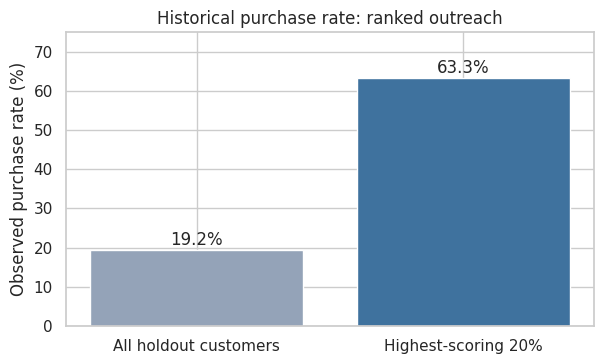

In [ ]:
# Evaluate the ranking under a fixed contact capacity
capacity = metrics["top20_contact_count"]
identified = metrics["top20_actual_buyers"]
summary = pd.DataFrame({
    "Measure": ["Customers contacted", "Historical purchasers found",
                "Purchase rate in selected leads", "Share of all purchasers captured",
                "Lift against random selection"],
    "Value": [f"{capacity:,} of {len(pred):,} ({capacity / len(pred):.1%})",
              f"{identified:,}", f"{metrics['top20_precision']:.1%}",
              f"{metrics['top20_recall']:.1%}", f"{metrics['top20_lift']:.2f}×"]
})
display(summary)

# Buying rate among the selected pool vs the full test cohort
fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.bar(["All holdout customers", "Highest-scoring 20%"],
       [100 * model_card["holdout_positive_rate"], 100 * metrics["top20_precision"]],
       color=["#94a3b8", "#3f729e"])
ax.set_ylim(0, 75)
ax.set_ylabel("Observed purchase rate (%)")
ax.set_title("Historical purchase rate: ranked outreach")
for i, v in enumerate([100 * model_card["holdout_positive_rate"],
                       100 * metrics["top20_precision"]]):
    ax.text(i, v + 1.3, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

**Observation:**
- Among the **166 highest-scoring customers**, **105 had purchased historically**, giving a **63.3%** observed purchase rate.
- This represents a **3.29× lift** over the overall holdout purchase rate and captures **66.0%** of purchasers using approximately one-fifth of the contact capacity.
- The improvement is estimated retrospectively. A controlled marketing campaign is needed to establish whether using the scores improves future conversions.

### 6.2 Feature importance and model integrity

,importance
MonthlyIncome,0.153
Age,0.147
Passport,0.118
NumberOfTrips,0.074
Designation_Executive,0.051
PreferredPropertyStar,0.050
NumberOfChildrenVisiting,0.036
NumberOfPersonVisiting,0.033
MaritalStatus_Single,0.031
Designation_Manager,0.028


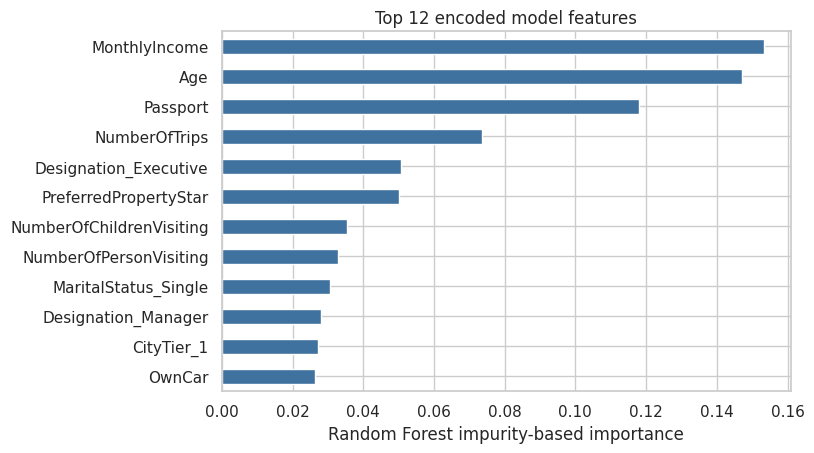

In [ ]:
# Inspect relative importance of the encoded model inputs
processor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]
expanded_names = processor.get_feature_names_out()
importance = (pd.Series(classifier.feature_importances_, index=expanded_names)
                .sort_values(ascending=False))

display(importance.head(12).rename("importance").to_frame())
fig, ax = plt.subplots(figsize=(8.3, 4.7))
importance.head(12).sort_values().plot.barh(ax=ax, color="#3f729e")
ax.set_xlabel("Random Forest impurity-based importance")
ax.set_title("Top 12 encoded model features")
plt.tight_layout()
plt.show()

In [ ]:
# Confirm that the published model can score new records after serialization
loaded_model = joblib.load(MODEL_PATH)
example = X_test.head(3)
score = loaded_model.predict_proba(example)[:, 1]
np.testing.assert_allclose(score, best_model.predict_proba(example)[:, 1])
display(pd.DataFrame({
    "estimated_propensity": score.round(4),
    "historical_outcome": y_test.head(3).to_numpy()
}))
print("Saved-model score consistency: PASSED")

,estimated_propensity,historical_outcome
0,0.050,0
1,0.099,0
2,0.334,0


Saved-model score consistency: PASSED


**Observation:**
- Feature importance shows which encoded inputs the fitted Random Forest relies on most, but **importance is not evidence of causality**.
- Predictions from the saved `.joblib` file exactly match the in-memory model for the sample tested. This confirms that the deployment artifact includes the fitted transformations and classifier.

## 7. Streamlit Deployment Component

The Streamlit interface loads the saved model, collects the same **13 pre-contact inputs**, assembles them into a DataFrame in the training feature order and returns a purchase-propensity score. The app also displays its model limitations and evaluation metadata.

### 7.1 Prediction application

In [ ]:
%%writefile tourism_project/deployment/app.py
"""Streamlit Community Cloud app: prospective historical-purchase propensity."""
from __future__ import annotations
import json
from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

DEPLOY_DIR = Path(__file__).resolve().parent
MODEL_FILE = DEPLOY_DIR / "best_model.joblib"
METADATA_FILE = DEPLOY_DIR / "model_metadata.json"
st.set_page_config(page_title="Visit with Us | Lead Prioritisation", page_icon="🌿", layout="wide")

@st.cache_resource
def get_model():
    return joblib.load(MODEL_FILE)

st.title("🌿 Visit with Us · Lead Prioritisation")
st.write("Predict **historical travel-package purchase propensity** using information available *before* sales contact.")
st.info("Research prototype: historical package outcomes are not verified Wellness Tourism Package outcomes. Validate on wellness-specific labelled customers before commercial rollout.")
if not MODEL_FILE.exists() or not METADATA_FILE.exists():
    st.error("Trained model not found. Run the GitHub Actions pipeline and commit best_model.joblib before deployment.")
    st.stop()
model = get_model()
metadata = json.loads(METADATA_FILE.read_text(encoding="utf-8"))

with st.form("customer"):
    st.subheader("Prospective customer profile")
    c1,c2,c3 = st.columns(3)
    with c1:
        age=st.number_input("Age", min_value=18, max_value=100, value=37)
        city=st.selectbox("City tier", [1,2,3])
        occupation=st.selectbox("Occupation", ["Salaried","Small Business","Large Business","Free Lancer"])
        gender=st.selectbox("Gender", ["Female","Male"])
        marital=st.selectbox("Marital status", ["Married","Single","Unmarried","Divorced"])
    with c2:
        people=st.number_input("People visiting", min_value=1,max_value=20,value=3)
        stars=st.selectbox("Preferred hotel stars", [3,4,5])
        trips=st.number_input("Trips per year", min_value=0,max_value=30,value=3)
        passport=st.selectbox("Valid passport", [0,1], format_func=lambda x:"Yes" if x else "No")
        car=st.selectbox("Owns a car", [0,1], format_func=lambda x:"Yes" if x else "No")
    with c3:
        children=st.number_input("Children under 5 visiting",min_value=0,max_value=10,value=1)
        designation=st.selectbox("Job designation", ["Executive","Manager","Senior Manager","AVP","VP"])
        income=st.number_input("Gross monthly income (dataset units)",min_value=0,max_value=300000,value=23000,step=500)
        st.caption("Use the same income units as the training dataset; its currency was not specified.")
    submitted=st.form_submit_button("Score customer", type="primary", use_container_width=True)

if submitted:
    row = {
        "Age":float(age), "NumberOfPersonVisiting":int(people),
        "PreferredPropertyStar":int(stars), "NumberOfTrips":int(trips),
        "Passport":int(passport), "OwnCar":int(car),
        "NumberOfChildrenVisiting":int(children), "MonthlyIncome":float(income),
        "Occupation":occupation, "Gender":gender, "MaritalStatus":marital,
        "Designation":designation,"CityTier":int(city)
    }
    df = pd.DataFrame([row], columns=metadata["feature_names"])
    score = float(model.predict_proba(df)[0,1])
    st.metric("Estimated historical-purchase propensity", f"{score:.1%}")
    st.progress(min(1.0, max(0.0, score)))
    if score >= metadata["decision_threshold"]:
        st.success("Above the illustrative 50% score threshold. Consider for priority review.")
    else:
        st.write("Below the illustrative 50% threshold. Consider ranking with the wider lead pool before allocating contact capacity.")
    st.caption("A prediction is not a guaranteed purchase. Scores are not proven calibrated; benchmark campaign lift prospectively.")

with st.expander("Model card and governance", expanded=False):
    st.write("**Model:**",metadata["model_family"])
    st.write("**Training choice:**",metadata["selection_criterion"])
    st.write("**Holdout average precision:**",f"{metadata['test_metrics']['average_precision']:.3f}")
    st.write("**Holdout top-20% lift:**",f"{metadata['test_metrics']['top20_lift']:.2f}×")
    st.write("**Inputs:** 13 pre-contact fields; no pitch or follow-up variables")
    st.write("**Limitations:** target is past product purchase; monitor data drift, disparate outcomes, and retrain only with labelled customers")


Overwriting tourism_project/deployment/app.py


### 7.2 Application and training dependencies

In [ ]:
%%writefile tourism_project/deployment/requirements.txt
# Streamlit Community Cloud; keep serialization stack consistent with training.
numpy==2.2.6
pandas==2.2.3
scikit-learn==1.8.0
joblib==1.5.3
streamlit==1.48.1


Overwriting tourism_project/deployment/requirements.txt


In [ ]:
%%writefile tourism_project/requirements.txt
# Training / CI dependencies; Python 3.11 across GitHub Actions and Community Cloud
numpy==2.2.6
pandas==2.2.3
scikit-learn==1.8.0
joblib==1.5.3
mlflow==3.0.1
pytest==8.4.2


Overwriting tourism_project/requirements.txt


**Observation:**
- The app uses the **same serialized estimator** selected during experimentation; it does not retrain a model when a customer is scored.
- The Streamlit form collects only information available before contact. The application distinguishes historical purchase propensity from a proven wellness-package conversion prediction.

## 8. Automated MLOps Workflow with GitHub Actions

The workflow runs four dependent stages: **dataset validation → data preparation → model training and experiment logging → model publication**. Training and testing partitions are passed between jobs as artifacts. The publishing job commits the selected model and its metadata to the repository.

### 8.1 Workflow definition

In [ ]:
%%writefile .github/workflows/pipeline.yml
name: Tourism propensity — validate, prepare, train and publish

on:
  push:
    branches: [main]
    paths-ignore:
      - "tourism_project/deployment/best_model.joblib"
      - "tourism_project/deployment/model_metadata.json"
      - "tourism_project/outputs/**"
      - "**/*.md"
  workflow_dispatch:

permissions:
  contents: write

concurrency:
  group: tourism-mlops-${{ github.ref }}
  cancel-in-progress: false

jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install project dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Validate and register data
        run: python -m tourism_project.model_building.data_register
      - uses: actions/upload-artifact@v4
        with:
          name: registered-data
          path: |
            tourism_project/data/tourism.csv
            tourism_project/outputs/registration_report.json

  data-prep:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install project dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Download and verify registered data
        uses: actions/download-artifact@v4
        with:
          name: registered-data
          path: tourism_project/registered-artifact
      - name: Confirm repository input agrees with artifact
        run: cmp tourism_project/data/tourism.csv tourism_project/registered-artifact/data/tourism.csv
      - name: Clean and split data
        run: python -m tourism_project.model_building.prep
      - uses: actions/upload-artifact@v4
        with:
          name: prepared-splits
          path: |
            tourism_project/outputs/Xtrain.csv
            tourism_project/outputs/Xtest.csv
            tourism_project/outputs/ytrain.csv
            tourism_project/outputs/ytest.csv
            tourism_project/outputs/preparation_report.json

  model-training:
    needs: data-prep
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
          cache: pip
          cache-dependency-path: tourism_project/requirements.txt
      - name: Install project dependencies
        run: pip install -r tourism_project/requirements.txt
      - name: Download training and holdout splits
        uses: actions/download-artifact@v4
        with:
          name: prepared-splits
          path: tourism_project/outputs
      - name: Tune candidates, track MLflow trials, export best model
        run: python -m tourism_project.model_building.train
      - name: Run offline scoring smoke tests
        run: python -m pytest -q tests
      - uses: actions/upload-artifact@v4
        with:
          name: model-and-evaluation
          path: |
            tourism_project/deployment/best_model.joblib
            tourism_project/deployment/model_metadata.json
            tourism_project/outputs/experiment_trials.json
            tourism_project/outputs/holdout_predictions.csv
            tourism_project/outputs/mlruns/

  publish-model:
    needs: model-training
    runs-on: ubuntu-latest
    if: github.ref == 'refs/heads/main'
    steps:
      - uses: actions/checkout@v4
        with:
          ref: main
          persist-credentials: true
      - name: Retrieve winner and its evaluation
        uses: actions/download-artifact@v4
        with:
          name: model-and-evaluation
          path: tourism_project/published-artifact
      - name: Commit binary model and model card to main
        shell: bash
        run: |
          set -euo pipefail
          cp tourism_project/published-artifact/deployment/best_model.joblib tourism_project/deployment/
          cp tourism_project/published-artifact/deployment/model_metadata.json tourism_project/deployment/
          git config user.name 'github-actions[bot]'
          git config user.email '41898282+github-actions[bot]@users.noreply.github.com'
          git add tourism_project/deployment/best_model.joblib tourism_project/deployment/model_metadata.json
          if git diff --cached --quiet; then
            echo 'No new model changes to publish'
          else
            git commit -m 'ci: publish trained model [skip ci]'
            git push origin HEAD:main
          fi


Overwriting .github/workflows/pipeline.yml


### 8.2 Automated pipeline checks

In [ ]:
%%writefile tests/test_pipeline.py
"""Lightweight CI checks; train script has already produced the model in Actions."""
import json
from pathlib import Path
import joblib
import pandas as pd
from tourism_project.model_building.config import (DATA_PATH, FEATURE_COLUMNS,
    MODEL_PATH, METADATA_PATH)
from tourism_project.model_building.data_register import validate_dataset
from tourism_project.model_building.prep import clean_data
from tourism_project.model_building.train import top_fraction_metrics


def test_registration_schema():
    report=validate_dataset(DATA_PATH)
    assert report["rows"] == report["unique_customers"]
    assert 0 < report["historical_purchase_rate"] < 1


def test_pre_contact_fields_and_canonical_gender():
    cleaned=clean_data(pd.read_csv(DATA_PATH))
    assert cleaned.drop(columns=["ProdTaken"]).columns.tolist() == FEATURE_COLUMNS
    assert "Fe Male" not in set(cleaned["Gender"])
    assert "DurationOfPitch" not in cleaned


def test_exported_model_scores():
    assert MODEL_PATH.exists() and METADATA_PATH.exists()
    model=joblib.load(MODEL_PATH)
    metadata=json.loads(METADATA_PATH.read_text(encoding="utf-8"))
    X=clean_data(pd.read_csv(DATA_PATH))[FEATURE_COLUMNS].head(4)
    probabilities=model.predict_proba(X)[:,1]
    assert len(probabilities)==4
    assert all(0 <= p <=1 for p in probabilities)
    assert metadata["feature_names"]==FEATURE_COLUMNS


def test_targeting_lift_math():
    m=top_fraction_metrics([1,0,0,0,0], [0.9,0.4,0.3,0.2,0.1], 0.2)
    assert m["top20_precision"] == 1.0
    assert m["top20_lift"] == 5.0


Overwriting tests/test_pipeline.py


In [ ]:
# Syntax checks and end-to-end smoke tests for generated project files
import ast
import subprocess
import yaml

workflow = yaml.safe_load(Path(".github/workflows/pipeline.yml").read_text())
expected_jobs = ["register-dataset", "data-prep", "model-training", "publish-model"]
assert list(workflow["jobs"]) == expected_jobs
ast.parse(Path("tourism_project/deployment/app.py").read_text())

verification = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"],
                              text=True, capture_output=True, check=True)
print("GitHub Actions YAML: VALID")
print("App Python syntax: VALID")
print(verification.stdout)

GitHub Actions YAML: VALID
App Python syntax: VALID
....                                                                     [100%]
4 passed in 1.23s



**Observation:**
- The workflow defines all **four required jobs**, with artifact handoffs and a model-publication stage.
- Local checks passed for data validation, feature selection, model loading and targeting-lift calculations.
- The linked GitHub Actions run completed successfully across all four jobs. The Streamlit deployment and an example customer prediction are documented in Section 9.

## 9. Output Evaluation

The GitHub repository contains the project files and executable workflow. The completed GitHub Actions run and Streamlit application demonstrate the hosted pipeline and customer-scoring interface. The links and screenshots below provide evidence of the repository structure, successful workflow execution and application output.


**GitHub Repository:**
https://github.com/don-pedro-W/visit-with-us-tourism-mlops

**GitHub Repository Screenshot:**

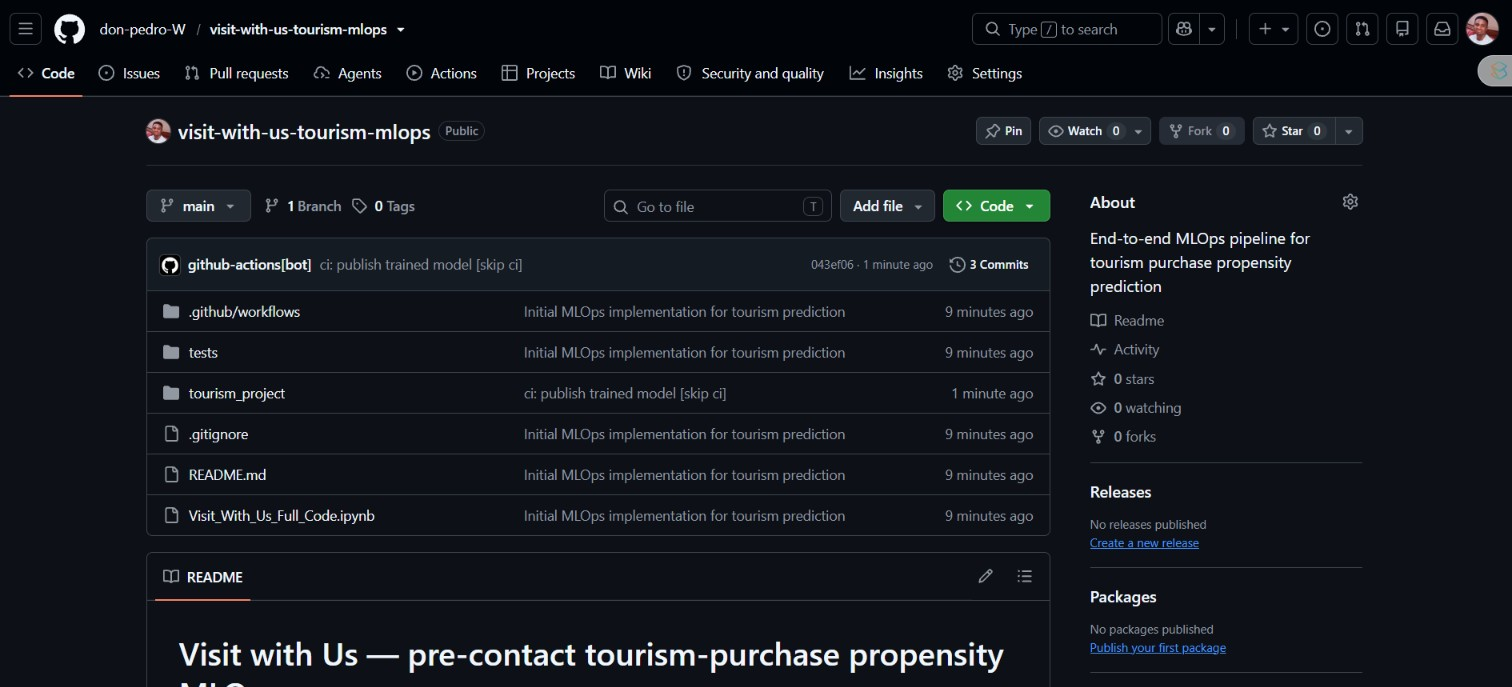

**Executed GitHub Actions Workflow:**
https://github.com/don-pedro-W/visit-with-us-tourism-mlops/actions/runs/43770872056

**Executed GitHub Actions Workflow Screenshot:**

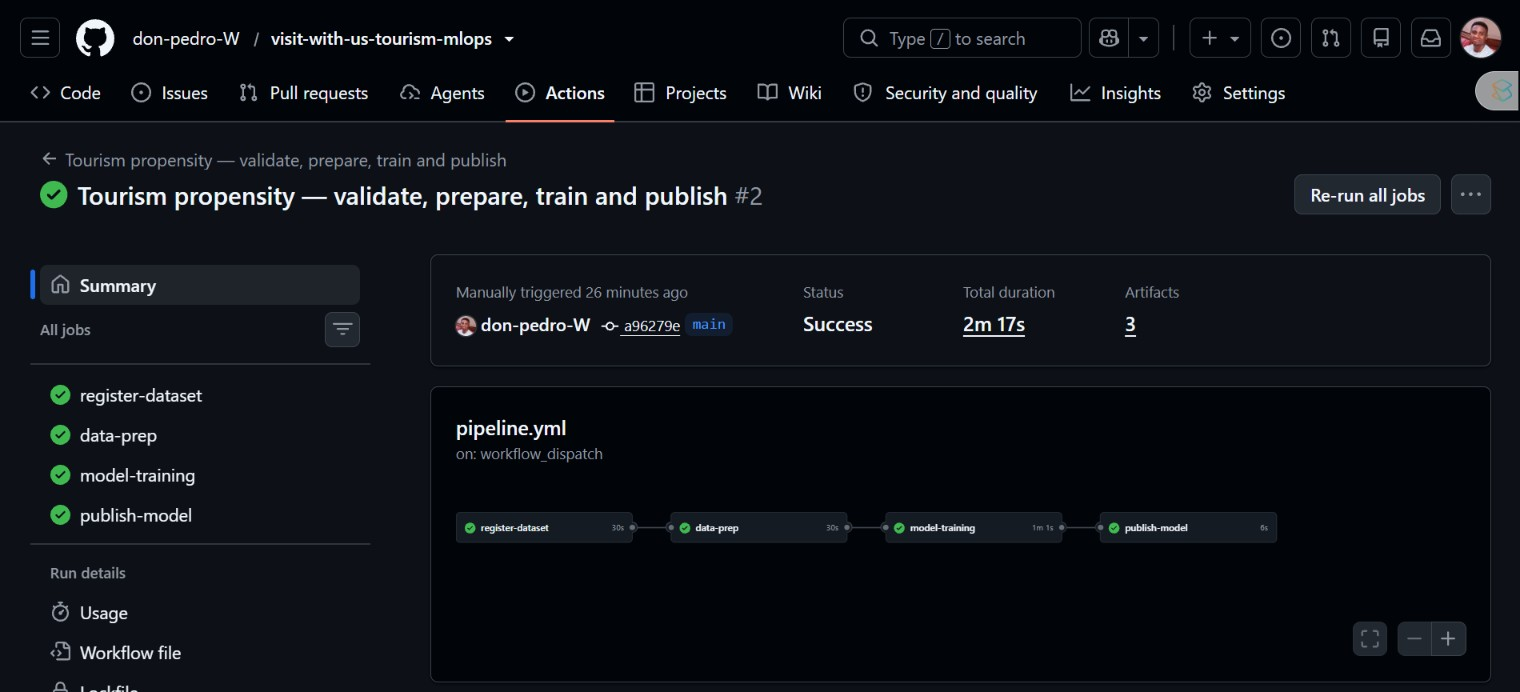

**Streamlit Community Cloud App:**
https://visit-with-us--mlops.streamlit.app/

**Streamlit Community Cloud App Screenshot:**

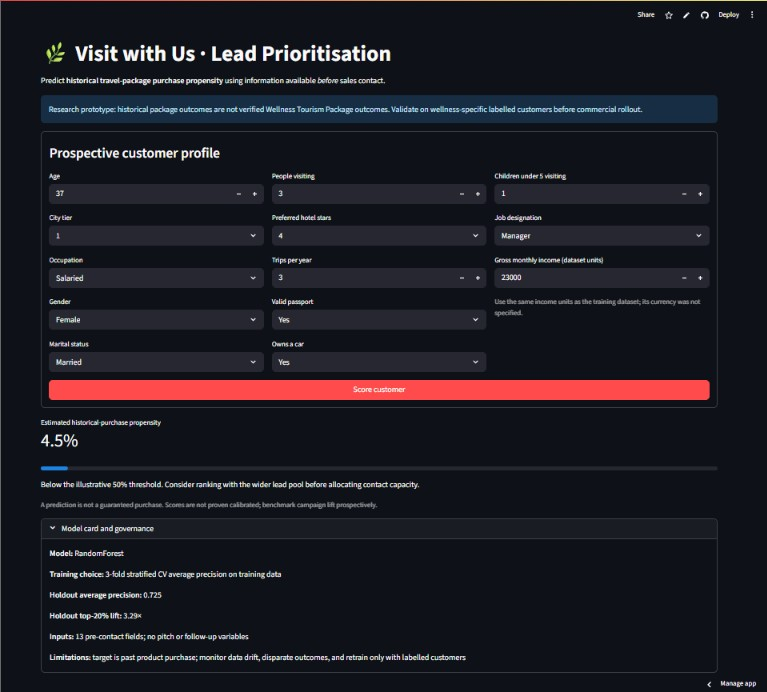

## 10. Conclusions and Business Recommendations

The Random Forest model provides a practical way to rank historical travel-package buyers using available pre-contact customer information. Its **0.725 holdout average precision** and **3.29× lift** within the highest-scoring 20% suggest that ranked outreach could make better use of limited marketing capacity.

**Recommendations**

1. **Pilot score-ranked outreach.** Compare a top-scored customer group with a comparable business-as-usual group. Measure incremental conversions, cost per acquisition and campaign margin.
2. **Use capacity-based selection.** Prioritise the highest-scoring customers within the team's available call volume. The 50% decision threshold is illustrative and should not automatically determine campaign allocation.
3. **Improve data consistency.** Correct the gender-label variation, clarify the meaning of `Single` versus `Unmarried`, and investigate unusual trip counts and the pitched-product/designation relationship.
4. **Validate the new product separately.** Collect labelled outcomes for actual Wellness Tourism Package offers and reassess model performance before broad deployment.
5. **Monitor model quality.** Record prediction distributions, changing customer profiles and performance by relevant customer groups. Retrain when recent, trustworthy labelled examples become available.

**Final assessment:** The locally executed checks, successful GitHub Actions run and documented Streamlit deployment provide evidence of an operational end-to-end prediction workflow. Its potential marketing value still requires prospective evaluation using actual Wellness Tourism Package purchase outcomes.